# 11 · Evaluation, calibration, and uncertainty

**Question.** What evidence would justify saying one system is better than another?

[Download the executed notebook](https://chikuang.github.io/teaching/genai/notebooks/11-evaluation-uncertainty.ipynb)

An evaluation begins with a target population and a loss, not with a leaderboard. We will compare paired system outcomes, estimate uncertainty by resampling questions, examine calibration and abstention, and construct finite-label conformal prediction sets. All numerical outcomes in this chapter are simulated; they illustrate statistical procedures rather than measure any commercial or pretrained model.

**Prerequisites:** Chapters 1, 6, and 10; sampling distributions and quantiles. **Outcomes:** define an estimand; preserve pairing; separate calibration from discrimination; interpret risk–coverage curves; state a conformal guarantee precisely.

## Pipeline and framework

![Define the task and sample unit, split and freeze choices, then calibrate on separate data and report final test metrics with uncertainty that respects dependence. Remember: separate selection, calibration, and the final test.](https://chikuang.github.io/teaching/genai/_static/diagrams/11-evaluation.png)

Evaluation is a **data-use protocol**, not a final call to a metric function. Write down which sample is allowed to influence each choice before fitting anything. In the executable classifier example, temperature is fitted on a validation sample, the conformal threshold is computed on a different calibration sample, and both are evaluated on a test sample.

| Data or artifact | Permitted role | Prohibited shortcut |
|:--|:--|:--|
| Development data | Choose prompts, architectures, retrieval settings, and stopping rules. | Repeatedly choosing settings on the final test outcomes. |
| Probability-fitting data | Fit a calibration map such as temperature scaling. | Claiming out-of-sample calibration from fitted-sample reliability alone. |
| Conformal calibration data | Compute a quantile after the score function is fixed. | Reusing those labels to tune the same score function without an appropriate method. |
| Final test data | Estimate locked-system performance and uncertainty. | Treating multiple calls on one task as independent sampled tasks. |

The framework has two outputs: a performance estimate and an account of what it generalizes to. For a system comparison, pair outputs on the same questions. For repeated agent trials, preserve the task cluster. For conformal sets, state the marginal guarantee and exchangeability requirement rather than reading the guarantee as certainty for every subgroup or individual question.

## 11.1 · Define the estimand and the unit

Let $Q$ be a question drawn from the intended task population and $U$ represent generation randomness. A system's risk is $R=\mathbb E[\ell(f(Q,U),Y)]$. A comparison might target $R_B-R_A$ under a fixed model version, prompt, retrieval collection, and decoding budget. Changing any of these changes the procedure under evaluation.

The sampling unit is usually the question, user, document, or task family, not each token and not necessarily each generation. Repeated answers to the same question share difficulty and evidence. If questions share documents, resample documents or use another method appropriate to that dependence.

## 11.2 · Preserve pairing when comparing systems

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(11)
n = 240
difficulty = rng.normal(size=n)
p_a = 1/(1+np.exp(-(0.6-difficulty)))
p_b = 1/(1+np.exp(-(0.85-difficulty)))
# A shared uniform variable creates correlated outcomes on the same questions.
u = rng.random(n)
correct_a = u < p_a
correct_b = u < p_b
difference = correct_b.astype(float)-correct_a.astype(float)
bootstrap_ids = rng.integers(n, size=(3000, n))
bootstrap_difference = difference[bootstrap_ids].mean(1)
interval = np.quantile(bootstrap_difference, [0.025, 0.975])
print('Accuracy A / B:', correct_a.mean().round(3), correct_b.mean().round(3))
print('Paired accuracy difference B-A:', round(difference.mean(), 3))
print('Question-bootstrap percentile interval:', interval.round(3))

Accuracy A / B: 0.638 0.692
Paired accuracy difference B-A: 0.054
Question-bootstrap percentile interval: [0.025 0.083]


The shared random variable is a convenient simulation construction, not an assumption that real model errors are nested. Resampling the paired differences preserves the observed association between systems. Resampling A and B independently would estimate a different sampling variance.

A percentile bootstrap interval is an approximation, not an exact finite-sample guarantee. Its interpretation depends on the sampled tasks representing the target population. It does not account for an unreported search over prompts or models using the same test set.

### Why pairing changes uncertainty

For independent sampled questions, let $A_i,B_i\in\{0,1\}$ indicate correctness and $D_i=B_i-A_i$. The accuracy estimand and estimator are

$$
\Delta=\mathbb E[D_i],\qquad \widehat\Delta=\frac1n\sum_iD_i,\qquad
\widehat{\operatorname{SE}}(\widehat\Delta)=\frac{s_D}{\sqrt n},
$$

where $s_D^2=(n-1)^{-1}\sum_i(D_i-\widehat\Delta)^2$. The population identity

$$
\operatorname{Var}(D_i)=\operatorname{Var}(B_i)+\operatorname{Var}(A_i)
-2\operatorname{Cov}(A_i,B_i)
$$

explains why independently resampling the two systems loses information. The code resamples whole paired differences to estimate uncertainty in Equation [(57)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-paired-difference), using bootstrap quantiles rather than its normal-approximation standard error. For zero-one loss, the risk difference $R_B-R_A=-\Delta$; report the direction so a positive improvement is not mistaken for a larger loss.

## 11.3 · Separate factual labels from judging machinery

For open-ended answers, define a rubric before viewing system identities: factual support, completeness, relevance, and required abstention may need separate labels. Use blinded ordering and audit disagreements. An LLM judge is another measurement instrument, with potential style preferences, positional effects, and shared errors with the evaluated system.

Report how labels were obtained and whether repeated annotations are independent. A high judge score is not automatically factual correctness. When feasible, include exact-answer checks or evidence-grounded human adjudication for a subset and quantify disagreement rather than silently resolving it in favor of one system.

## 11.4 · Calibration is a relationship between probabilities and outcomes

For binary outcomes, calibration informally asks whether events assigned probability $p$ occur at frequency $p$. A model can rank cases well while being overconfident. The Brier score averages $(p-y)^2$; log loss strongly penalizes confidently wrong probabilities. A binned reliability plot is descriptive and depends on bin definitions and sample size.

### Calibration and temperature scaling in symbols

For a binary probability prediction $P\in[0,1]$, population calibration means

$$
\mathbb E[Y\mid P]=P\quad\text{almost surely}.
$$

It does not require a continuous predictor to take any exact prespecified value with positive probability. Bins estimate averages of this relationship. On $n$ evaluation cases, the Brier score is $n^{-1}\sum_i(p_i-y_i)^2$; it measures overall probability error, not calibration alone.

For fixed logits $z_i$, temperature fitting on the separate validation index set $\mathcal V$ is

$$
\widehat\tau\in\operatorname*{arg\min}_{\tau\in\mathcal T}
\frac1{|\mathcal V|}\sum_{i\in\mathcal V}
\left[\log(1+e^{z_i/\tau})-y_i z_i/\tau\right],
\qquad \widetilde p_i=\sigma(z_i/\widehat\tau).
$$

$\mathcal T\subset(0,\infty)$ is the finite grid used below. `logaddexp` evaluates the first term stably. Positive temperature preserves binary ranking and the zero-logit decision boundary; it can improve probabilities without changing 0.5-threshold accuracy. Fitting Equation [(59)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-temperature-fit) does not guarantee the population calibration property in Equation [(58)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-calibration).

Below a fixed simulated predictor is deliberately overconfident. A temperature is selected using a validation sample. We then evaluate on a disjoint test sample; a separate calibration sample is reserved for conformal prediction.

Validation-selected temperature: 1.925
Raw Brier: 0.22
Temperature-scaled Brier: 0.207


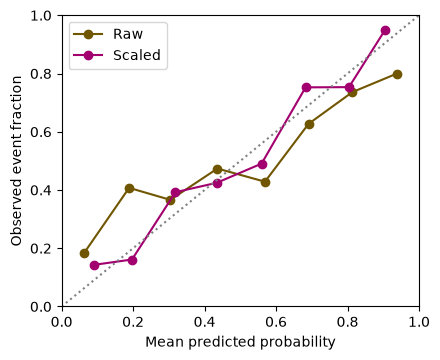

In [2]:
n_total = 1400
latent = rng.normal(size=n_total)
true_p = 1/(1+np.exp(-latent))
y = rng.binomial(1, true_p)
logits = 2.0 * latent
validation = np.arange(300)
calibration = np.arange(300, 800)
test = np.arange(800, n_total)

def sigmoid(z):
    return 1/(1+np.exp(-z))

def binary_loss(z, labels):
    return np.mean(np.logaddexp(0, z)-labels*z)

temperatures = np.linspace(0.5, 3.5, 121)
validation_losses = [binary_loss(logits[validation]/t, y[validation]) for t in temperatures]
temperature = temperatures[np.argmin(validation_losses)]
raw_p = sigmoid(logits[test])
calibrated_p = sigmoid(logits[test]/temperature)
print('Validation-selected temperature:', round(temperature, 3))
for label, p in [('Raw', raw_p), ('Temperature-scaled', calibrated_p)]:
    print(label, 'Brier:', round(np.mean((p-y[test])**2), 3))

fig, ax = plt.subplots(figsize=(4.5, 3.7))
for label, p, color in [('Raw', raw_p, '#705600'),
                       ('Scaled', calibrated_p, '#a2006e')]:
    bins = np.minimum((p*8).astype(int), 7)
    points = [(p[bins==b].mean(), y[test][bins==b].mean())
              for b in range(8) if np.sum(bins==b) >= 10]
    ax.plot(*np.array(points).T, 'o-', label=label, color=color)
ax.plot([0, 1], [0, 1], ':', color='gray')
ax.set(xlabel='Mean predicted probability', ylabel='Observed event fraction',
       xlim=(0, 1), ylim=(0, 1))
ax.legend()
plt.tight_layout()
plt.show()

Temperature scaling preserves the ranking of binary logits when temperature is positive. It changes probability calibration, not the underlying evidence. Token probabilities from a language model are probabilities of token events under that model; they are not automatically probabilities that a whole answer is factually correct.

## 11.5 · Abstention produces a risk–coverage tradeoff

Let $c_i$ be a confidence score and answer only if $c_i\ge\tau$. Coverage is the answered fraction. Selective risk is the average loss among answered cases. Both quantities matter.

For $A_\tau=\mathbf1\{c(Q)\ge\tau\}$ and a fixed system loss $L$, the population quantities are

$$
\operatorname{Coverage}(\tau)=\mathbb P(A_\tau=1),\qquad
\operatorname{Risk}(\tau)=\frac{\mathbb E[L A_\tau]}{\mathbb E[A_\tau]}.
$$

The empirical counterparts of Equation [(60)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-risk-coverage) are $n^{-1}\sum_i A_{\tau i}$ and $\sum_i\ell_i A_{\tau i}/\sum_i A_{\tau i}$. Selective risk is defined only at positive coverage. In this lab $c_i=\max(\widetilde p_i,1-\widetilde p_i)$ and $\ell_i$ is a binary classification error. These definitions also apply to answer/abstain decisions in RAG after defining a suitable answer-level loss and confidence score.

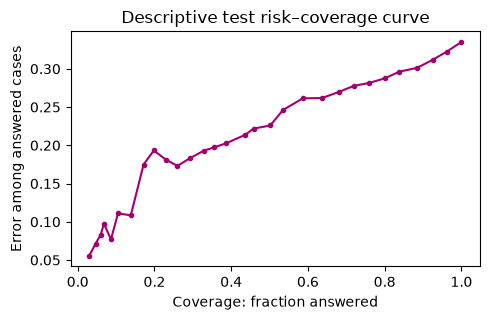

In [3]:
confidence = np.maximum(calibrated_p, 1-calibrated_p)
prediction = calibrated_p >= 0.5
errors = (prediction != y[test]).astype(float)
thresholds = np.linspace(0.5, 0.9, 30)
coverage, risk = [], []
for threshold in thresholds:
    selected = confidence >= threshold
    if selected.any():
        coverage.append(selected.mean())
        risk.append(errors[selected].mean())
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.plot(coverage, risk, 'o-', markersize=3, color='#a2006e')
ax.set(xlabel='Coverage: fraction answered', ylabel='Error among answered cases',
       title='Descriptive test risk–coverage curve')
plt.tight_layout()
plt.show()

This curve is descriptive. If you use it to choose the operating threshold, this test sample has become development data. For a final evaluation, choose the threshold on a separate development set and report uncertainty on a new test set. Risk can also worsen within an important subgroup even when overall selective risk improves.

## 11.6 · Split conformal prediction for a finite label space

We now construct sets of labels in $\{0,1\}$ using a predictor fixed before the conformal calibration sample is examined. For calibration case $i$, use nonconformity score $s_i=1-\widehat p_{y_i}(x_i)$. With $n_c$ calibration cases, let $k=\lceil(n_c+1)(1-\alpha)\rceil$ and take the kth smallest score. If $k>n_c$, use an infinite threshold. The set is

$$
C(x)=\{y:1-\widehat p_y(x)\le \widehat q\}.
$$

Under exchangeability of calibration and future examples, with the predictor fixed independently of these calibration outcomes, this construction gives marginal coverage at least $1-\alpha$. Ties make the nonrandomized version potentially conservative. The guarantee is over calibration and future examples jointly, not a guarantee of coverage conditional on every covariate value.

In symbols, with $s_{(k)}$ the kth ordered calibration score,

$$
\widehat q=\begin{cases}s_{(k)},&k\le n_c,\\+\infty,&k=n_c+1,\end{cases}
\quad k=\lceil(n_c+1)(1-\alpha)\rceil,\quad 0<\alpha<1,
$$

$$
\mathbb P_{\mathcal D_{\mathrm{cal}},(X_{\mathrm{new}},Y_{\mathrm{new}})}
\{Y_{\mathrm{new}}\in C(X_{\mathrm{new}})\}\ge 1-\alpha.
$$

Equation [(63)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-conformal-coverage) applies to the set in Equation [(61)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-conformal-set) with the threshold in Equation [(62)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-conformal-quantile). For distinct exchangeable scores, the new score's rank among $n_c+1$ scores is uniform; choosing this rank gives the finite-sample correction. Ties with the displayed non-strict inclusion preserve the lower bound. The probability averages over both a new calibration sample and a future case, conditional on the independently fitted predictor; it is not a statement that every realized calibration sample or every covariate subgroup has coverage $1-\alpha$. See the [split-conformal construction](https://arxiv.org/abs/2107.07511).

In [4]:
alpha = 0.1
p_cal = sigmoid(logits[calibration]/temperature)
P_cal = np.column_stack([1-p_cal, p_cal])
scores = 1-P_cal[np.arange(len(calibration)), y[calibration]]
k = int(np.ceil((len(scores)+1)*(1-alpha)))
q = np.sort(scores)[k-1] if k <= len(scores) else np.inf
P_test = np.column_stack([1-calibrated_p, calibrated_p])
sets = (1-P_test) <= q
covered = sets[np.arange(len(test)), y[test]]
print('Calibration size / rank / quantile:', len(scores), k, round(q, 3))
print('Empirical test coverage:', round(covered.mean(), 3))
print('Average set size:', round(sets.sum(1).mean(), 3))
print('Empty / singleton / doubleton counts:', np.bincount(sets.sum(1), minlength=3))

Calibration size / rank / quantile: 500 451 0.672
Empirical test coverage: 0.89
Average set size: 1.517
Empty / singleton / doubleton counts: [  0 290 310]


The observed test fraction can lie below the nominal level in one finite sample. Equation [(63)](https://chikuang.github.io/teaching/genai/chapters/11-evaluation-uncertainty.html#equation-eq-conformal-coverage) does not assert that every test batch achieves the target exactly. Larger prediction sets may deliver coverage while being less informative. Evaluate both coverage and set size.

A set of finite class labels is not a set of all semantically correct free-text answers. Applying conformal ideas to generated text requires specifying an assessable target, a score, and assumptions appropriate to that target. Distribution shift, adaptive reuse of calibration data, and dependence can invalidate a naive guarantee.

## 11.7 · Exercises and worked solutions

1. **Paired estimator:** write the estimand for the accuracy difference. **Solution:** $\mathbb E[1\{B\text{ correct}\}-1\{A\text{ correct}\}]$ on the target task distribution. The sample mean of question-level differences estimates it under representative sampling.
2. **Repeated generations:** why are 20 answers to each of 10 questions not 200 independent questions? **Solution:** repetitions share a task. They help estimate within-question generation variability but provide only 10 question clusters for variation across tasks.
3. **Conformal rank:** with $n_c=99$ and $\alpha=0.1$, which order statistic is used? **Solution:** $\lceil100(0.9)\rceil=90$. The finite-sample correction uses $n_c+1$, not simply an interpolated 90th percentile.
4. **Calibration leakage:** can temperature be chosen using the same outcomes later used for an ordinary split-conformal quantile? **Solution:** that violates the simple fixed-predictor calibration argument. Use a separate fitting/validation sample or a method whose proof accounts for that data reuse.
5. **No answers:** what is selective risk when no cases are answered? **Solution:** it is undefined because its denominator is zero. Report zero coverage and an undefined risk, not a perfect zero error rate.
6. **Scope of coverage:** does 90% marginal coverage imply 90% coverage for each subgroup? **Solution:** no. Marginal guarantees average across the target distribution. Group-specific guarantees require additional design and assumptions.

## 11.8 · Reading and next step

[A Gentle Introduction to Conformal Prediction](https://arxiv.org/abs/2107.07511) provides the formal framework and extensions behind the finite-label exercise. Next, [Chapter 12](https://chikuang.github.io/teaching/genai/chapters/12-agents.html) adds sequential tool decisions, which introduces new units of evaluation and additional failure modes.